# 4 · Aprendizaje de máquina: predecir
**Torre del Caribe** · Universidad Nacional Rosario Castellanos · Licenciatura en Ciencia de Datos para Negocios, 5.º
semestre 2026-2 · Equipo 2

| | |
|---|---|
| **Materia (UCA)** | Aprendizaje de Máquina |
| **Profesor** | Raúl Jorge Domínguez Vilchis |
| **Criterio de la rúbrica** | 4. Aprendizaje de máquina (12 %) |
| **Equipo** | Brandon Uriel García Sánchez · Maribel Mondragón Mercado · Jesús Ramírez Isidro · Enrique González Ortega |

La campaña necesita dos predicciones: **cómo va a estar cada lugar el mes que viene** (para pausar un
anuncio antes de que un lugar se llene) y **cuántos visitantes llegarán en los próximos 12 meses** (para saber en qué
meses hay espacio). La primera es un problema de **clasificación**; la segunda, de **pronóstico de series de tiempo**.
En los dos casos la regla es la misma: un modelo solo vale si le gana a una respuesta sencilla, y se prueba siempre con
meses que el modelo no vio.

| Parte | Qué respondemos |
|---|---|
| 1. Clasificación | ¿Qué estado tendrá cada lugar el mes siguiente? |
| 2. Entrenar, validar y probar | ¿Con qué meses se elige el modelo y con cuáles se mide? |
| 3. Pronóstico de visitantes | ¿Cuántos visitantes llegarán en los próximos 12 meses? |
| 4. El rango del 90 % | ¿Qué tan seguro es cada pronóstico? |
| 5. La elección y el pronóstico final | ¿Qué modelo usa cada lugar y qué dice? |
| 6. Resumen de hiperparámetros | Cada valor que elegimos, por qué y qué descartamos |

**Cómo leer este notebook.** Antes de cada celda de código explicamos qué hacemos y por qué; dentro del código, cada
renglón lleva su comentario. Al terminar cada paso comparamos nuestro resultado con el que guardó el proyecto (función
`coincide`): si una cifra no coincidiera, el notebook se detendría ahí. El documento técnico del equipo
(*Torre_del_Caribe.pdf*) tiene las fórmulas con su ejemplo resuelto a mano.

**Cómo correrlo.** Python 3.11 con `pip install -r requirements.txt` desde la carpeta de la entrega; abrir en Jupyter o
VS Code y elegir *Ejecutar todo*. Ya viene ejecutado, así que también se puede leer sin correrlo.

In [1]:
%matplotlib inline
# Preparación. Buscamos la carpeta de la entrega (la que tiene datos/silver), cargamos las librerías,
# definimos el estilo de las gráficas y la función que compara nuestras cifras con las del proyecto.
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

warnings.filterwarnings("ignore")                        # avisos de versiones de librerías que no cambian resultados
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datos" / "silver").is_dir())
SILVER, GOLD = RAIZ / "datos" / "silver", RAIZ / "datos" / "gold"   # datos limpios y resultados del proyecto
FIGURAS = Path.cwd() / "figuras"                          # aquí guardamos cada gráfica como PNG
FIGURAS.mkdir(exist_ok=True)

# Colores institucionales de la UNRC (guinda y dorado) y una paleta para varias series.
GUINDA, DORADO, GRIS = "#9F2241", "#BC955C", "#3A3A3A"
PALETA = ["#9F2241", "#BC955C", "#565393", "#58A65D", "#8CAFDD", "#F26E50", "#465973"]
for f in (RAIZ / "herramientas" / "fuentes").glob("NotoSans-*.ttf"):
    font_manager.fontManager.addfont(str(f))          # la letra Noto Sans viene en la entrega
plt.rcParams.update({"font.family": "Noto Sans", "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlecolor": GUINDA, "axes.titlesize": 12,
                     "text.color": GRIS, "axes.labelcolor": GRIS, "xtick.color": GRIS, "ytick.color": GRIS,
                     "figure.facecolor": "white", "savefig.dpi": 160, "savefig.bbox": "tight"})
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)


def coincide(nombre, nuestro, proyecto, tolerancia=1e-6):
    """Compara un resultado de este notebook con el que guardó el proyecto. Si no coincide, se detiene."""
    a = np.asarray(nuestro, dtype=float).ravel()
    b = np.asarray(proyecto, dtype=float).ravel()
    assert a.shape == b.shape, f"{nombre}: tamaños distintos {a.shape} y {b.shape}"
    dif = float(np.nanmax(np.abs(a - b))) if len(a) else 0.0
    print(f"{'✓' if dif <= tolerancia else '✗'} {nombre}: coincide con el proyecto (diferencia máxima {dif:.2g})")
    assert dif <= tolerancia, f"{nombre} no coincide con el proyecto"


def guardar(fig, nombre):
    """Guarda la gráfica en figuras/ con un nombre claro."""
    fig.savefig(FIGURAS / f"{nombre}.png")


print("Carpeta de la entrega:", RAIZ)

Carpeta de la entrega: C:\Users\Uriel\Desktop\PP 5to semestre CASCO SANTO TOMAS\Entregable


## 1. Clasificación: el estado del mes siguiente
### De dónde sale el estado
En el notebook 3 (Minería) construimos el **índice de presión turística (IPT)** de 14 lugares de Quintana Roo, mes por
mes: el promedio de varias medidas de presión (llegadas en tren por habitante, ocupación hotelera, visitantes por cuarto,
etc.) puestas en la misma escala. Con los percentiles 50 y 90 del índice, cada mes de cada lugar queda en un estado:
*tranquilo*, *concurrido* o *saturado*. Aquí partimos de esa tabla.

**La pregunta de aprendizaje de máquina:** con lo que se sabe en el mes $t$, ¿en qué estado estará el lugar en $t+1$?

In [2]:
t = pd.read_parquet(GOLD / "radar_indice_comparable.parquet")          # el índice de cada lugar y mes (notebook 3)
ESTADOS = ["tranquilo", "concurrido", "saturado"]
print(f"{t.lugar.nunique()} lugares · {t.periodo.min():%Y-%m} a {t.periodo.max():%Y-%m} · "
      f"cortes del estado: p50 = {t.corte_p50.iloc[0]:.3f}, p90 = {t.corte_p90.iloc[0]:.3f}")
t.dropna(subset=["ipt_comparable"]).groupby("lugar").agg(meses=("periodo", "size"), medidas=("medidas", "first"))

14 lugares · 2022-01 a 2026-07 · cortes del estado: p50 = 0.186, p90 = 0.756


,meses,medidas
lugar,,
Bacalar,20,"llegadas_tren_x1000hab, visitantes_inah_x1000hab, llegadas_x_cuarto"
Bahía Calderitas–Oxtankah,55,visitantes_inah_x1000hab
Cancún,31,"llegadas_tren_x1000hab, visitantes_inah_x1000hab, llegadas_x_cuarto, ocupaci..."
Chetumal,20,"llegadas_tren_x1000hab, llegadas_x_cuarto"
Costa Mujeres,36,ocupacion_pct
Cozumel,55,"cruceristas_x1000hab, visitantes_inah_x1000hab, llegadas_x_cuarto, ocupacion..."
Holbox,24,"llegadas_tren_x1000hab, llegadas_x_cuarto"
Isla Mujeres,55,ocupacion_pct
Mahahual,55,"cruceristas_x1000hab, llegadas_x_cuarto"


### Los rasgos (lo que el modelo puede ver)
Para cada lugar y mes armamos una fila con lo que **ya se sabía** ese mes y, como respuesta, el estado del mes siguiente:

| Rasgo | Qué es | Por qué lo incluimos |
|---|---|---|
| `ipt_comparable` | El índice de este mes | El mejor indicio de cómo estará el siguiente |
| `ipt_1`, `ipt_2` | El índice de hace 1 y 2 meses | Para ver si viene subiendo o bajando |
| `cambio` | Índice de hoy menos el de hace un mes | La velocidad del cambio, directa |
| `mes_sin`, `mes_cos` | El mes del año como un punto en un círculo | La temporada. Con el número del mes (1 a 12), diciembre y enero quedarían lejos; en el círculo quedan juntos |
| `es_de_los_5` | 1 si es uno de los 5 lugares de la campaña | Los del sur se comportan distinto (casi siempre tranquilos) |

Descartamos meter variables del clima o del tipo de cambio: no se conocen para el mes siguiente al momento de
predecir, y meter su valor real sería "ver el futuro".

In [3]:
filas = []
for _, g in t.groupby("lugar"):
    g = g.sort_values("periodo").copy()
    g["ipt_1"] = g.ipt_comparable.shift(1)                             # el índice del mes anterior
    g["ipt_2"] = g.ipt_comparable.shift(2)                             # el de hace dos meses
    g["cambio"] = g.ipt_comparable - g.ipt_1                           # cuánto cambió en el último mes
    g["estado_hoy"] = g.estado
    g["objetivo"] = g.estado.shift(-1)                                 # lo que queremos predecir: el estado del mes siguiente
    g["periodo_objetivo"] = g.periodo.shift(-1)
    filas.append(g)
d = pd.concat(filas, ignore_index=True)
d["mes_sin"] = np.sin(2 * np.pi * d.periodo.dt.month / 12)           # el mes como ángulo de un círculo
d["mes_cos"] = np.cos(2 * np.pi * d.periodo.dt.month / 12)
d["es_de_los_5"] = d.es_de_los_5.astype(int)
d = d.dropna(subset=["ipt_comparable", "ipt_1", "ipt_2", "objetivo"]).reset_index(drop=True)   # solo filas completas
RASGOS = ["ipt_comparable", "ipt_1", "ipt_2", "cambio", "mes_sin", "mes_cos", "es_de_los_5"]
print(f"{len(d)} filas para aprender · objetivo:", d.objetivo.value_counts().to_dict())

468 filas para aprender · objetivo: {'tranquilo': 234, 'concurrido': 185, 'saturado': 49}


Las clases están **desbalanceadas**: *saturado* es solo el 10 % de los casos. Por eso dos decisiones:
los modelos usan `class_weight="balanced"` (un error en *saturado* pesa más) y medimos también el **F1-macro**, que
promedia el F1 de las tres clases por igual. Con la exactitud sola, un modelo que nunca dice "saturado" se vería bien.

### Los modelos que comparamos
| Modelo | Cómo decide | Hiperparámetros y por qué |
|---|---|---|
| **Persistencia** (línea base) | "El mes que viene estará igual que este" | Ninguno. Es la respuesta sencilla a vencer: los estados duran varios meses |
| **Regresión logística** | Suma ponderada de los rasgos → probabilidad de cada estado | Rasgos estandarizados (media 0, desviación 1) para que ningún rasgo pese solo por su escala; `max_iter=2000` para que el ajuste termine; regularización por defecto (`C=1`) |
| **Random Forest** | 400 árboles de decisión, cada uno con una muestra distinta; vota la mayoría | `n_estimators=400`: con más árboles el voto ya no cambia; `min_samples_leaf=3`: cada hoja con al menos 3 casos, para que un árbol no memorice un mes raro |
| **Gradient Boosting** | Árboles chicos en cadena, cada uno corrige los errores del anterior | Los valores de scikit-learn (100 árboles de profundidad 3, tasa 0.1), un punto de partida estándar |

Los tres fijan `random_state=0` donde hay azar, para que los resultados se puedan repetir. **No buscamos los
hiperparámetros con una búsqueda en rejilla**: con 136 casos de validación, probar decenas de combinaciones y quedarse
con la mejor sería elegir por suerte. Más abajo mostramos que los resultados casi no cambian con valores cercanos.

**Qué otros modelos descartamos.** Redes neuronales: con 468 filas no hay datos para entrenarlas. k vecinos más cercanos
y máquinas de vectores de soporte (SVM): los probamos abajo, en la validación, y quedan debajo de la persistencia.

In [4]:
import time
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def modelos():
    """Modelos nuevos cada vez (sin nada aprendido), con los hiperparámetros del proyecto."""
    return {"Regresión logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
            "Random Forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=3, class_weight="balanced", random_state=0),
            "Gradient Boosting": GradientBoostingClassifier(random_state=0)}

## 2. Entrenar, validar y probar
En series de tiempo **nunca** se parten los datos al azar: si un mes de 2026 cae en el entrenamiento y uno de 2025 en la
prueba, el modelo aprende del futuro. Usamos tres periodos, siempre en orden:

| Periodo | Meses objetivo | Para qué |
|---|---|---|
| **Entrenamiento** | Todo lo anterior a cada mes que se predice | Aprender |
| **Validación** | ago-2024 a jul-2025 (136 casos) | **Elegir** el modelo |
| **Prueba** | ago-2025 a jul-2026 (156 casos) | **Medir**, una sola vez, con un modelo ya elegido |

En los dos últimos usamos **origen móvil**: para cada mes reentrenamos con todo lo anterior y predecimos solo ese mes.
Son 12 reentrenamientos por periodo, como si cada mes hubiéramos corrido el modelo de verdad.

**Lo que se mide.** Aciertos; *cambios acertados* (meses en que el estado sí cambió y el modelo lo anticipó; la
persistencia nunca acierta uno); *falsas alarmas* (anunció un cambio que no pasó); y F1-macro.

**El criterio para elegir** (decisión del equipo): el modelo con más aciertos en la validación y, si empatan, el que
anticipa más cambios, porque anticipar que un lugar se va a llenar es lo que necesita la regla anti-colapso.

In [5]:
def origen_movil(desde, hasta, fabrica=modelos):
    """Para cada mes objetivo en [desde, hasta): entrena con todo lo anterior y predice ese mes."""
    meses = sorted(d.loc[(d.periodo_objetivo >= desde) & (d.periodo_objetivo < hasta), "periodo_objetivo"].unique())
    y, hoy, preds = [], [], {}
    for mes in meses:
        ent, pru = d[d.periodo_objetivo < mes], d[d.periodo_objetivo == mes]   # pasado para entrenar, el mes para probar
        y.append(pru.objetivo.to_numpy()); hoy.append(pru.estado_hoy.to_numpy())
        preds.setdefault("Persistencia (línea base)", []).append(pru.estado_hoy.to_numpy())
        for nombre, m in fabrica().items():
            m.fit(ent[RASGOS], ent.objetivo)
            preds.setdefault(nombre, []).append(m.predict(pru[RASGOS]))
    y, hoy = np.concatenate(y), np.concatenate(hoy)
    cambia = y != hoy                                                  # meses en que el estado sí cambió
    filas = []
    for nombre, p in preds.items():
        p = np.concatenate(p)
        filas.append({"modelo": nombre, "aciertos": int((y == p).sum()), "casos": len(y),
                      "cambios_acertados": int((y == p)[cambia].sum()), "cambios_reales": int(cambia.sum()),
                      "falsas_alarmas": int(((p != hoy) & (p != y)).sum()),   # predijo un cambio que no ocurrió
                      "f1_macro": round(f1_score(y, p, average="macro", labels=ESTADOS, zero_division=0), 3)})
    return pd.DataFrame(filas).set_index("modelo"), y, preds

PRUEBA = pd.Timestamp("2025-08-01")
VALIDACION = PRUEBA - pd.DateOffset(months=12)
FIN = d.periodo_objetivo.max() + pd.Timedelta(days=1)
inicio = time.time()
val, _, _ = origen_movil(VALIDACION, PRUEBA)
pru, y_prueba, preds_prueba = origen_movil(PRUEBA, FIN)
print(f"24 reentrenamientos de 3 modelos en {time.time() - inicio:.0f} s")
proyecto = pd.read_parquet(GOLD / "radar_modelos.parquet").set_index("modelo")
coincide("aciertos en la validación", val.aciertos, proyecto.aciertos_validacion.reindex(val.index))
coincide("aciertos en la prueba", pru.aciertos, proyecto.aciertos.reindex(pru.index))
pd.concat({"VALIDACIÓN (aquí se elige)": val, "PRUEBA (aquí solo se mide)": pru}, axis=1)

24 reentrenamientos de 3 modelos en 15 s
✓ aciertos en la validación: coincide con el proyecto (diferencia máxima 0)
✓ aciertos en la prueba: coincide con el proyecto (diferencia máxima 0)


VALIDACIÓN (aquí se elige)                                                                PRUEBA (aquí solo se mide)                                                        \
                                            aciertos casos cambios_acertados cambios_reales falsas_alarmas f1_macro                   aciertos casos cambios_acertados cambios_reales falsas_alarmas   
modelo                                                                                                                                                                                                 
Persistencia (línea base)                        119   136                 0             17              0    0.845                        126   156                 0             30              0   
Regresión logística                              112   136                 8             17             15    0.794                        130   156                 8             30              4   
Random Forest                                    122   136                 4             17              1    0.867                        130   156                 6             30              2   
Gradient Boosting                                111   136                 2             17             10    0.751                        128   156                 7             30              5   

                                    
                          f1_macro  
modelo                              
Persistencia (línea base)    0.774  
Regresión logística          0.793  
Random Forest                0.766  
Gradient Boosting            0.731

**La elección.** En la validación, **Random Forest** acierta 122 de 136 y es el único que le gana a la
persistencia (119). La regresión logística (112) y Gradient Boosting (111) quedan debajo: anticipan algunos cambios, pero
a cambio de muchas falsas alarmas (15 y 10).

**La medición.** Ya elegido, en la prueba Random Forest acierta **130 de 156** contra 126 de la persistencia, anticipa 6
de los 30 cambios y solo da 2 falsas alarmas. Le gana a la respuesta sencilla en meses que nunca vio, ni para entrenar ni
para elegir.

**Por qué importa separar validación y prueba.** Si hubiéramos elegido con los meses de la prueba, la regresión logística
habría empatado en aciertos con Random Forest. Y si hubiéramos probado más modelos ahí, habría ganado uno que en la
validación queda debajo de la persistencia (la SVM, en la celda de abajo). Elegir con los mismos meses con que se
reporta el resultado premia al modelo que tuvo suerte en esos meses. Esta separación la agregamos en la revisión final
del proyecto (decisión 32); antes estaba elegida la regresión logística.

In [6]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

def variantes():
    """Valores cercanos a los elegidos y otros dos modelos, solo para ver qué tan estable es el resultado."""
    return {"Logística C = 0.1": make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000, class_weight="balanced")),
            "Logística C = 10": make_pipeline(StandardScaler(), LogisticRegression(C=10, max_iter=2000, class_weight="balanced")),
            "Random Forest 100 árboles": RandomForestClassifier(100, min_samples_leaf=3, class_weight="balanced", random_state=0),
            "Random Forest hoja ≥ 1": RandomForestClassifier(400, min_samples_leaf=1, class_weight="balanced", random_state=0),
            "Random Forest hoja ≥ 10": RandomForestClassifier(400, min_samples_leaf=10, class_weight="balanced", random_state=0),
            "Gradient Boosting tasa 0.05, prof. 2": GradientBoostingClassifier(learning_rate=0.05, max_depth=2, random_state=0),
            "k vecinos (k = 15)": make_pipeline(StandardScaler(), KNeighborsClassifier(15)),
            "SVM (kernel RBF)": make_pipeline(StandardScaler(), SVC(class_weight="balanced"))}

sens_val, _, _ = origen_movil(VALIDACION, PRUEBA, variantes)
sens_pru, _, _ = origen_movil(PRUEBA, FIN, variantes)
pd.DataFrame({"aciertos validación": sens_val.aciertos, "aciertos prueba": sens_pru.aciertos,
              "falsas alarmas validación": sens_val.falsas_alarmas}).drop(index="Persistencia (línea base)")

,aciertos validación,aciertos prueba,falsas alarmas validación
modelo,,,
Logística C = 0.1,111,127,16
Logística C = 10,113,128,15
Random Forest 100 árboles,122,130,1
Random Forest hoja ≥ 1,121,132,4
Random Forest hoja ≥ 10,119,125,3
"Gradient Boosting tasa 0.05, prof. 2",114,125,6
k vecinos (k = 15),106,127,22
SVM (kernel RBF),114,133,15


**Cómo se lee.** Con 100 o 400 árboles, Random Forest da lo mismo (122): más árboles ya no cambian el
voto. Con hojas de al menos 10 casos el bosque se vuelve demasiado simple y pierde aciertos (119); con hojas de 1 queda
casi igual (121). Nuestros valores están en la zona estable. La SVM es el ejemplo de lo que evitamos: en la prueba
acierta 133, pero en la validación solo 114 (debajo de la persistencia). Si la hubiéramos elegido por la prueba, en el
siguiente año probablemente habría fallado.

### Dónde se equivoca el modelo elegido
La **matriz de confusión** cruza el estado real (renglones) con el predicho (columnas) en los 156 casos de prueba.

In [7]:
p_rf = np.concatenate(preds_prueba["Random Forest"])
mc = pd.DataFrame(confusion_matrix(y_prueba, p_rf, labels=ESTADOS), index=[f"real {e}" for e in ESTADOS],
                  columns=[f"predicho {e}" for e in ESTADOS])
f1_clase = f1_score(y_prueba, p_rf, labels=ESTADOS, average=None)   # el F1 de cada estado
print("F1 por estado:", dict(zip(ESTADOS, f1_clase.round(3))), "· F1-macro:", round(f1_clase.mean(), 3))
mc

F1 por estado: {'tranquilo': 0.884, 'concurrido': 0.79, 'saturado': 0.625} · F1-macro: 0.766


,predicho tranquilo,predicho concurrido,predicho saturado
real tranquilo,76,11,0
real concurrido,9,49,4
real saturado,0,2,5


### ¿El modelo es justo con el sur? (sesgo)
Un riesgo del aprendizaje de máquina en turismo es que funcione bien donde hay muchos datos (el norte) y mal donde hay
pocos (el sur). Separamos los aciertos de la prueba entre los 5 lugares de la campaña y el resto del estado.

In [8]:
r = d[d.periodo_objetivo >= PRUEBA].sort_values(["periodo_objetivo", "lugar"]).copy()
partes = []
for mes in sorted(r.periodo_objetivo.unique()):                      # el mismo origen móvil, guardando cada predicción
    ent, x = d[d.periodo_objetivo < mes], d[d.periodo_objetivo == mes]
    m = modelos()["Random Forest"].fit(ent[RASGOS], ent.objetivo)
    partes.append(x.assign(pred=m.predict(x[RASGOS])))
r = pd.concat(partes)
filas = []
for grupo, g in r.groupby("es_de_los_5"):
    cambia = g.objetivo != g.estado_hoy
    filas.append({"grupo": "5 lugares" if grupo else "resto del estado", "casos": len(g),
                  "exactitud_modelo": round(accuracy_score(g.objetivo, g.pred), 3),
                  "exactitud_persistencia": round(accuracy_score(g.objetivo, g.estado_hoy), 3),
                  "cambios_reales": int(cambia.sum()), "cambios_acertados": int((g.pred == g.objetivo)[cambia].sum())})
sesgo = pd.DataFrame(filas)
coincide("sesgo (5 lugares contra el resto)", sesgo[["casos", "exactitud_modelo", "cambios_acertados"]],
         pd.read_parquet(GOLD / "radar_sesgo.parquet")[["casos", "exactitud_modelo", "cambios_acertados"]])
sesgo

✓ sesgo (5 lugares contra el resto): coincide con el proyecto (diferencia máxima 0)


,grupo,casos,exactitud_modelo,exactitud_persistencia,cambios_reales,cambios_acertados
0,resto del estado,108,0.778,0.741,28,6
1,5 lugares,48,0.958,0.958,2,0


En los 5 lugares el modelo acierta 46 de 48 (95.8 %), **igual que la persistencia**: en ese año el sur
casi no cambió de estado (2 cambios), así que ahí el modelo no se puede validar. Lo declaramos como limitación y por eso
la Torre en vivo (notebook 6) vigila cada semana si la predicción se cumple.

### La predicción de agosto de 2026
Reentrenamos Random Forest con **todo** lo disponible y predecimos el mes siguiente al último publicado. La columna lleva
`_est` porque es una estimación, no una medición.

In [9]:
final = modelos()["Random Forest"].fit(d[RASGOS], d.objetivo)
ultimo = t.dropna(subset=["ipt_comparable"]).periodo.max()
filas = []
for lugar, g in t.groupby("lugar"):
    g = g.sort_values("periodo").dropna(subset=["ipt_comparable"])
    if len(g) < 3 or g.periodo.iloc[-1] != ultimo:                    # un lugar sin dato reciente no se predice
        continue
    filas.append({"lugar": lugar, "es_de_los_5": int(g.es_de_los_5.iloc[-1]), "periodo": g.periodo.iloc[-1],
                  "estado_hoy": g.estado.iloc[-1], "ipt_comparable": g.ipt_comparable.iloc[-1],
                  "ipt_1": g.ipt_comparable.iloc[-2], "ipt_2": g.ipt_comparable.iloc[-3]})
x = pd.DataFrame(filas)
x["cambio"] = x.ipt_comparable - x.ipt_1
x["mes_sin"], x["mes_cos"] = np.sin(2 * np.pi * x.periodo.dt.month / 12), np.cos(2 * np.pi * x.periodo.dt.month / 12)
x["estado_mes_siguiente_est"] = final.predict(x[RASGOS])
probs = pd.DataFrame(final.predict_proba(x[RASGOS]), columns=[f"P({c})" for c in final.classes_])
x = pd.concat([x, probs], axis=1)
proyecto = pd.read_parquet(GOLD / "radar_prediccion.parquet")
coincide("probabilidades de agosto de 2026", probs.to_numpy(), proyecto[[f"prob_{c}" for c in final.classes_]].to_numpy())
importancia = pd.Series(final.feature_importances_, index=RASGOS).sort_values(ascending=False)
print("Qué rasgos usa más el bosque:", importancia.round(3).to_dict())
x[["lugar", "estado_hoy", "estado_mes_siguiente_est", "P(tranquilo)", "P(concurrido)", "P(saturado)"]].round(2)

✓ probabilidades de agosto de 2026: coincide con el proyecto (diferencia máxima 0)
Qué rasgos usa más el bosque: {'ipt_comparable': 0.362, 'ipt_1': 0.241, 'ipt_2': 0.21, 'cambio': 0.073, 'es_de_los_5': 0.066, 'mes_cos': 0.031, 'mes_sin': 0.017}


,lugar,estado_hoy,estado_mes_siguiente_est,P(tranquilo),P(concurrido),P(saturado)
0,Bacalar,concurrido,concurrido,0.06,0.93,0.01
1,Bahía Calderitas–Oxtankah,tranquilo,tranquilo,1.00,0.00,0.00
2,Cancún,concurrido,tranquilo,0.59,0.41,0.01
3,Chetumal,tranquilo,tranquilo,1.00,0.00,0.00
4,Cozumel,concurrido,tranquilo,0.63,0.37,0.00
5,Holbox,concurrido,concurrido,0.19,0.81,0.00
6,Isla Mujeres,concurrido,concurrido,0.24,0.70,0.06
7,Mahahual,concurrido,saturado,0.01,0.44,0.55
8,Maya Ka'an + Kantemó,tranquilo,tranquilo,1.00,0.00,0.00
9,Playa del Carmen,tranquilo,tranquilo,0.70,0.30,0.00


Los 5 lugares del sur siguen **tranquilos** con probabilidad de 0.93 a 1.00: hay espacio y la campaña
puede anunciarlos. Mahahual (con cruceros) es el único con riesgo de saturarse (0.55). El bosque se apoya sobre todo en
el índice de este mes y de los meses anteriores; la temporada pesa menos.

## 3. Pronóstico de visitantes de 1 a 12 meses
### Las series
Pronosticamos solo series **medidas** que llegan a 2026: visitantes del INAH a la Bahía (Oxtankah) y a la Ruta de las
pirámides (Kohunlich, Dzibanché e Ichkabal), cruces desde Belice por Chetumal, y la ocupación hotelera de Cancún y de la
Riviera Maya como **referencia** (son el público de la campaña, no lugares que se promuevan).

**Los meses que no sirven para entrenar.** Un mes cerrado no es "cero demanda". Marcamos (y no usamos para aprender) los
meses de **cierre** (0 visitantes: pandemia, obras de 2024), los **meses parciales** (el de antes de cerrar y el de
reabrir) y la **pandemia** (mar-2020 a dic-2021 en el INAH; hasta jun-2022 en Belice, donde la frontera tardó en
recuperarse). El valor se conserva; solo se marca.

                                                    desde      hasta  meses  entrenan
serie                                                                                
Bahía Calderitas–Oxtankah · visitantes INAH    2016-01-01 2026-07-01    127        90
Cancún (referencia) · ocupación hotelera       2022-01-01 2026-07-01     55        55
Chetumal · cruces desde Belice                 2019-01-01 2026-06-01     90        62
Riviera Maya (referencia) · ocupación hotelera 2022-01-01 2026-07-01     55        55
Ruta arqueológica del sur · visitantes INAH    2016-01-01 2026-07-01    127        91


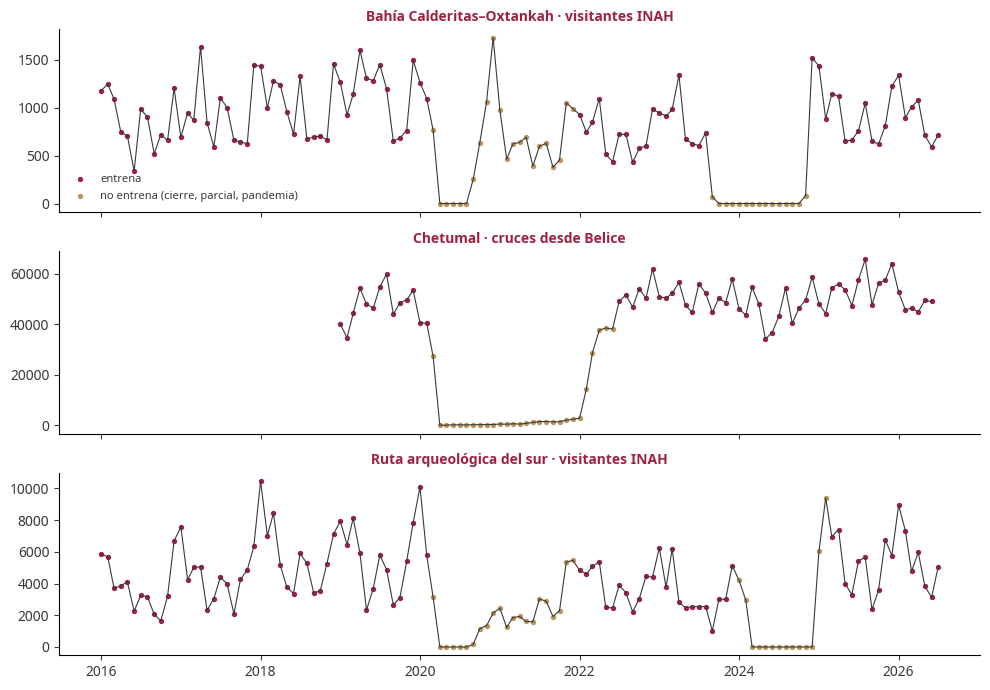

In [10]:
series = pd.read_parquet(GOLD / "pronostico_series.parquet")
print(series.groupby("serie").agg(desde=("periodo", "min"), hasta=("periodo", "max"), meses=("valor", "size"),
                                  entrenan=("entrena_flag", "sum")).to_string())

fig, ejes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, (s, g) in zip(ejes, [(s, g) for s, g in series.groupby("serie") if "INAH" in s or "Belice" in s]):
    ax.plot(g.periodo, g.valor, color=GRIS, lw=0.8)                                   # la serie completa
    ax.scatter(g.periodo[g.entrena_flag], g.valor[g.entrena_flag], s=8, color=GUINDA, label="entrena")
    ax.scatter(g.periodo[~g.entrena_flag], g.valor[~g.entrena_flag], s=8, color=DORADO, label="no entrena (cierre, parcial, pandemia)")
    ax.set_title(s, fontsize=10)
ejes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
guardar(fig, "4_series_a_pronosticar")

### La forma del año
Los cinco modelos usan, de una u otra forma, la **forma del año**: cuánto sube o baja cada mes contra el promedio del
año (lo explicamos en el notebook 3). Se calcula solo con **años completos** (los 12 meses entrenan) y, en cada
pronóstico, solo con años que terminaron **antes** del momento en que se pronostica.

$$S_m = \frac{\overline{r}_m}{\frac{1}{12}\sum_k \overline{r}_k}, \qquad r_{a,m} = \frac{y_{a,m}}{\bar y_a}$$

In [11]:
def anios_completos(s):
    n = s[s.entrena_flag].groupby(s.periodo.dt.year).size()
    return sorted(int(a) for a in n[n == 12].index)                    # años con los 12 meses útiles

def razones(s):
    """Tabla año × mes con valor ÷ promedio de su año, solo en años completos."""
    x = s[s.periodo.dt.year.isin(anios_completos(s))].copy()
    x["anio"], x["mes"] = x.periodo.dt.year, x.periodo.dt.month
    x["razon"] = x.valor / x.groupby("anio").valor.transform("mean")
    return x.pivot(index="anio", columns="mes", values="razon")

def indice_estacional(r):
    i = r.mean(axis=0)                                                 # promedio de cada mes entre años
    return i / i.mean()                                                # reescalado: los 12 promedian 1

def forma_hasta(s, origen):
    """La forma del año con años completos que terminaron antes del origen (sin ver el futuro)."""
    r = razones(s[s.periodo <= origen])
    r = r[r.index < origen.year + (1 if origen.month == 12 else 0)]
    return indice_estacional(r) if len(r) else None

def tramo_actual(s, origen):
    """Los meses útiles desde la última interrupción (cierre, pandemia) hasta el origen."""
    x = s[s.periodo <= origen].set_index("periodo")
    malos = x.index[~x.entrena_flag]
    desde = malos.max() if len(malos) else x.index.min() - pd.offsets.MonthBegin(1)
    return x.valor[(x.index > desde) & x.entrena_flag]

### Los cinco modelos
| # | Modelo | La idea |
|---|---|---|
| 0 | **Línea base (ingenuo estacional)** | El mes que viene vale lo mismo que ese mes la última vez (marzo 2026 = marzo 2025). Es la respuesta sencilla a vencer |
| 1 | **Holt-Winters con tendencia amortiguada** | Quita la temporada, sigue el nivel y la tendencia con suavizamiento exponencial (la tendencia se va apagando) y vuelve a poner la temporada |
| 2 | **Holt-Winters sin tendencia** | Igual, pero solo con el nivel. La agregamos porque la tendencia, aprendida en tramos cortos después de reabrir, se disparaba a 7–12 meses |
| 3 | **Regresión con clima** | $\ln(y) = $ nivel del tramo + efecto del mes + lluvia sobre lo normal + tormenta. Al pronosticar usa el clima normal (no se conoce el clima futuro) |
| 4 | **Gradient Boosting con rezagos** | Aprende de pares (mes de origen → mes destino) con el último valor, el promedio de los 3 últimos, el mismo mes del año anterior, el horizonte y el mes |

**Por qué Holt-Winters "con forma fija" y no el clásico.** El Holt-Winters clásico aprende la temporada de la serie
continua y necesita al menos 24 meses seguidos. Desde las reaperturas solo hay 20 (Bahía) y 17 (Ruta). Por eso la
temporada sale de los años completos anteriores y el nivel, del tramo actual.

**Por qué no SARIMA, Prophet o una red neuronal.** SARIMA también necesita una serie continua larga y nuestras series
tienen huecos de cierre. Prophet rellena los huecos con su propia curva y es difícil de explicar paso a paso. Una red
LSTM necesita miles de datos; aquí hay de 55 a 91 meses útiles por serie.

In [12]:
import warnings
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.ensemble import HistGradientBoostingRegressor

HORIZONTE, MIN_TRAMO = 12, 3        # 12 meses adelante; se necesitan ≥ 3 meses útiles desde la última reapertura

def ingenuo_estacional(s, origen, destinos):
    x = s[(s.periodo <= origen) & s.entrena_flag]
    ultimo = x.sort_values("periodo").groupby(x.periodo.dt.month).valor.last()   # el último valor de cada mes del año
    return np.array([ultimo.get(dd.month, np.nan) for dd in destinos])

def _holt(s, origen, destinos, tendencia):
    S, y = forma_hasta(s, origen), tramo_actual(s, origen)
    if S is None or len(y) < MIN_TRAMO:
        return np.full(len(destinos), np.nan)
    z = (y / y.index.month.map(S).values).to_numpy()                    # la serie sin temporada
    h = [(dd.year - origen.year) * 12 + dd.month - origen.month for dd in destinos]
    if len(z) < 6:                                                      # tramo muy corto: solo el promedio
        nivel = np.full(max(h), z.mean())
    else:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            if tendencia:
                nivel = ExponentialSmoothing(z, trend="add", damped_trend=True, initialization_method="estimated").fit().forecast(max(h))
            else:
                nivel = np.full(max(h), ExponentialSmoothing(z, initialization_method="estimated").fit().forecast(1)[0])
    return np.array([nivel[k - 1] * S[dd.month] for k, dd in zip(h, destinos)])      # se vuelve a poner la temporada

def holt_con_tendencia(s, origen, destinos):
    return _holt(s, origen, destinos, True)

def holt_sin_tendencia(s, origen, destinos):
    return _holt(s, origen, destinos, False)

Para la regresión con clima necesitamos la lluvia de cada mes (del reanálisis ERA5, que tiene la serie
mes a mes completa desde 1950; las normales del SMN son promedios de 30 años y no sirven para esto) y si ese mes empezó
una tormenta a 200 km de Chetumal (la misma definición del notebook 5).

In [13]:
PUNTO_CLIMA = {"Bahía Calderitas–Oxtankah": "chetumal", "Ruta arqueológica del sur": "kohunlich", "Chetumal": "chetumal",
               "Cancún": "cancun", "Riviera Maya": "playa_del_carmen"}
dia = pd.read_parquet(SILVER / "clima_diario", columns=["punto", "anio", "mes", "lluvia_mm"])
h = pd.read_parquet(SILVER / "huracanes", columns=["id_tormenta", "anio", "mes", "fecha", "hora_utc", "viento_kt", "km_chetumal"])
h = h.assign(anio=h.anio.astype(int), mes=h.mes.astype(int))
cerca = h[(h.km_chetumal <= 200) & (h.viento_kt >= 34) & (h.anio >= 1966)].sort_values(["fecha", "hora_utc"])
TORMENTAS = set(cerca.groupby("id_tormenta").first()[["anio", "mes"]].itertuples(index=False, name=None))   # (año, mes) de cada evento
CLIMA = {}

def clima_mensual(punto):
    """Lluvia total de cada mes y si ese mes empezó una tormenta que afectó al sur (0/1)."""
    if punto not in CLIMA:
        x = dia[dia.punto == punto].assign(anio=lambda z: z.anio.astype(int))
        c = x.groupby(["anio", "mes"]).lluvia_mm.sum().reset_index()
        c["tormenta"] = [int((a, m) in TORMENTAS) for a, m in zip(c.anio, c.mes)]
        c["periodo"] = pd.to_datetime(dict(year=c.anio, month=c.mes, day=1))
        CLIMA[punto] = c.set_index("periodo")
    return CLIMA[punto]

def regresion_con_clima(s, origen, destinos):
    x = s[s.periodo <= origen].sort_values("periodo").set_index("periodo")
    if len(tramo_actual(s, origen)) < MIN_TRAMO:
        return np.full(len(destinos), np.nan)
    clima = clima_mensual(PUNTO_CLIMA[s.lugar.iloc[0]])
    antes = clima[clima.index <= origen]                                # solo el clima que ya se conocía
    normal = antes.groupby("mes").lluvia_mm.mean()
    frec_tormenta = antes[antes.anio >= 1966].groupby("mes").tormenta.mean()
    tramo = (~x.entrena_flag).cumsum()[x.entrena_flag]                  # número de tramo de cada mes útil
    y = np.log(x.valor[tramo.index])
    cl = clima.reindex(tramo.index)
    X = pd.DataFrame(index=tramo.index)
    for k in sorted(tramo.unique()):
        X[f"tramo_{k}"] = (tramo == k).astype(float)                     # un nivel por tramo
    for m in range(2, 13):
        X[f"mes_{m}"] = (X.index.month == m).astype(float)               # 11 meses (enero es la referencia)
    X["lluvia_anom"] = (cl.lluvia_mm - cl.mes.map(normal)).to_numpy() / 100   # cientos de mm sobre lo normal
    X["tormenta"] = cl.tormenta.to_numpy()
    X = X.loc[:, X.abs().sum() > 0]                                     # sin columnas vacías
    beta, *_ = np.linalg.lstsq(X.to_numpy(), y.to_numpy(), rcond=None)  # mínimos cuadrados
    b = dict(zip(X.columns, beta))
    ult = f"tramo_{tramo.iloc[-1]}"
    return np.array([np.exp(b[ult] + b.get(f"mes_{dd.month}", 0.0) + b.get("tormenta", 0.0) * frec_tormenta.get(dd.month, 0.0))
                     for dd in destinos])                               # clima normal: anomalía 0, tormenta = frecuencia

def _rasgos(x, o, dd):
    antes = x[x.index <= o]
    if len(antes) < 3:
        return None
    mismo = antes[antes.index.month == dd.month]
    return [(dd.year - o.year) * 12 + dd.month - o.month, dd.month, np.log(antes.iloc[-1]), np.log(antes.iloc[-3:].mean()),
            np.log(mismo.iloc[-1]) if len(mismo) else np.nan]

def gradient_boosting(s, origen, destinos):
    x = s[(s.periodo <= origen) & s.entrena_flag].set_index("periodo").valor
    if len(tramo_actual(s, origen)) < MIN_TRAMO:
        return np.full(len(destinos), np.nan)
    X, y = [], []
    for o in x.index:                                                   # todos los pares pasados (origen → destino)
        for dd in x.index[(x.index > o) & (x.index <= o + pd.DateOffset(months=HORIZONTE))]:
            r_ = _rasgos(x, o, dd)
            if r_ is not None:
                X.append(r_); y.append(np.log(x[dd]))
    if len(X) < 50:
        return np.full(len(destinos), np.nan)
    m = HistGradientBoostingRegressor(max_iter=150, learning_rate=0.05, min_samples_leaf=20, random_state=0)
    m.fit(np.array(X), np.array(y))
    return np.exp(m.predict(np.array([_rasgos(x, origen, dd) for dd in destinos])))

MODELOS = {"Línea base (ingenuo estacional)": ingenuo_estacional, "Holt-Winters con tendencia amortiguada": holt_con_tendencia,
           "Holt-Winters sin tendencia": holt_sin_tendencia, "Regresión con clima": regresion_con_clima,
           "Gradient Boosting con rezagos": gradient_boosting}

**Los hiperparámetros del Gradient Boosting** son conservadores a propósito, porque hay pocos datos: 150
árboles con tasa de aprendizaje 0.05 (aprende despacio y no persigue el ruido) y hojas de al menos 20 casos (una regla
no se apoya en uno o dos meses). Pide al menos 50 pares para entrenar; con menos, no pronostica.

### El origen móvil
"Regresamos el reloj" a cada mes del pasado, pronosticamos de 1 a 12 meses con lo que se sabía entonces y comparamos con
lo que pasó. Solo cuentan los pares (origen, destino) que **los cinco modelos** pudieron pronosticar, para comparar
parejo. El primer origen de cada serie es cuando ya hay al menos un año completo antes.

In [14]:
PRIMER_ORIGEN = {"visitantes INAH": "2019-01-01", "Belice": "2023-06-01", "Cancún": "2023-01-01", "Riviera Maya": "2023-01-01"}
inicio = time.time()
filas = []
for serie, s in series.groupby("serie"):
    s = s.sort_values("periodo").reset_index(drop=True)
    util = s.set_index("periodo").entrena_flag
    primero = pd.Timestamp(next(v for k, v in PRIMER_ORIGEN.items() if k in serie))
    for origen in s.periodo[(s.periodo >= primero) & s.entrena_flag]:
        destinos = pd.date_range(origen + pd.offsets.MonthBegin(1), periods=HORIZONTE, freq="MS")
        destinos = destinos[destinos.isin(util.index[util])]          # solo meses destino que entrenan
        if len(destinos) == 0 or len(tramo_actual(s, origen)) < MIN_TRAMO:
            continue
        real = s.set_index("periodo").valor.reindex(destinos).to_numpy()
        for nombre, f in MODELOS.items():
            for dd, p_, r_ in zip(destinos, f(s, origen, destinos), real):
                filas.append({"serie": serie, "modelo": nombre, "origen": origen, "destino": dd,
                              "horizonte": (dd.year - origen.year) * 12 + dd.month - origen.month, "pronostico": p_, "real": r_})
b = pd.DataFrame(filas).dropna(subset=["pronostico"])
b = b[b.groupby(["serie", "origen", "destino"]).modelo.transform("nunique") == len(MODELOS)].reset_index(drop=True)
b["error_abs"] = (b.pronostico - b.real).abs()
b["error_pct"] = b.error_abs / b.real * 100
print(f"{len(b):,} pronósticos en {time.time() - inicio:.0f} s")
proyecto_b = pd.read_parquet(GOLD / "pronostico_backtest.parquet")
coincide("los 9,930 pronósticos del origen móvil", b.pronostico, proyecto_b.pronostico)

9,930 pronósticos en 57 s
✓ los 9,930 pronósticos del origen móvil: coincide con el proyecto (diferencia máxima 0)


### El error
Medimos el **MAE** (error absoluto medio, en las unidades de la serie) y el **MAPE** (error porcentual medio, para
comparar series distintas). La columna *vs base* es el MAE del modelo entre el MAE de la línea base: menos de 1 quiere
decir que le gana a "repetir el mismo mes del año pasado".

$$\text{MAE} = \frac{1}{n}\sum |\hat y - y|, \qquad \text{MAPE} = \frac{100}{n}\sum \frac{|\hat y - y|}{y}$$

In [15]:
b["tramo_h"] = pd.cut(b.horizonte, [0, 3, 6, 12], labels=["1–3", "4–6", "7–12"]).astype(str)   # horizonte cercano, medio, lejano
m = b.groupby(["serie", "modelo"]).agg(pronosticos=("error_abs", "size"), mae=("error_abs", "mean"), mape=("error_pct", "mean")).reset_index()
m["mae_vs_base"] = m.mae / m.serie.map(m[m.modelo.str.startswith("Línea base")].set_index("serie").mae)
por_h = b.pivot_table(index=["serie", "modelo"], columns="tramo_h", values="error_pct", aggfunc="mean")
m = m.merge(por_h.add_prefix("mape_h").reset_index(), on=["serie", "modelo"])
coincide("MAE por serie y modelo", m.mae.round(3), pd.read_parquet(GOLD / "pronostico_metricas.parquet").mae, tolerancia=1e-9)
m.pivot(index="modelo", columns="serie", values="mae_vs_base").round(2)

✓ MAE por serie y modelo: coincide con el proyecto (diferencia máxima 0)


serie,Bahía Calderitas–Oxtankah · visitantes INAH,Cancún (referencia) · ocupación hotelera,Chetumal · cruces desde Belice,Riviera Maya (referencia) · ocupación hotelera,Ruta arqueológica del sur · visitantes INAH
modelo,,,,,
Gradient Boosting con rezagos,1.40,1.04,0.99,1.08,1.07
Holt-Winters con tendencia amortiguada,1.52,1.84,1.24,1.93,0.93
Holt-Winters sin tendencia,1.08,1.68,0.97,1.72,0.64
Línea base (ingenuo estacional),1.00,1.00,1.00,1.00,1.00
Regresión con clima,0.90,1.58,0.82,1.44,0.74


## 4. El rango del 90 % (intervalo conformal)
Un pronóstico sin rango promete de más. Cada modelo tiene su propia fórmula de intervalo, pero suponen errores normales y
no existen igual para todos (la línea base y el Gradient Boosting no tienen). Usamos un método que trata a todos igual,
el **conformal**:

1. Medimos el error en escala logarítmica, $e = |\ln(\hat y / y)|$, porque la temporada es multiplicativa: así el rango
   es "± X %" y sirve igual en enero (mes alto) que en septiembre (mes bajo).
2. Para un pronóstico hecho en el origen $o$, juntamos los errores de pronósticos **anteriores** cuyo mes destino ya
   había pasado en $o$ (los que ya se conocían), del mismo modelo y del mismo tramo de horizonte.
3. El tamaño del rango es el cuantil $\lceil (n+1)\cdot 0.9 \rceil / n$ de esos errores, y el rango es
   $[\hat y\,e^{-q},\ \hat y\,e^{q}]$.

Ese cuantil garantiza cobertura de al menos 90 % **si los errores futuros se parecen a los pasados**. Por eso no lo
suponemos: medimos la **cobertura real**, cuántas veces el valor real cayó dentro.

In [16]:
import math
NIVEL, MIN_CALIBRACION = 0.90, 20

def cuantil_conformal(errores, nivel=NIVEL):
    n = len(errores)
    return float(np.sort(errores)[min(math.ceil((n + 1) * nivel), n) - 1])

b["error_log"] = np.abs(np.log((b.pronostico / b.real).where(b.pronostico > 0))).fillna(np.inf)   # un pronóstico ≤ 0 es error total
q = np.full(len(b), np.nan)
for _, g in b.groupby(["serie", "modelo", "tramo_h"]):
    destinos, errores = g.destino.to_numpy(), g.error_log.to_numpy()
    for i, o in zip(g.index, g.origen):
        cal = errores[destinos <= o]                                    # solo errores ya conocidos en el origen
        if len(cal) >= MIN_CALIBRACION:                                 # con menos de 20 no damos rango
            q[i] = cuantil_conformal(cal)
b["q_log"] = q
b["dentro"] = (b.real >= b.pronostico * np.exp(-b.q_log)) & (b.real <= b.pronostico * np.exp(b.q_log))
cob = b.dropna(subset=["q_log"]).groupby(["serie", "modelo"]).agg(con_rango=("dentro", "size"), cobertura_pct=("dentro", "mean"),
                                                                  ancho=("q_log", "median")).reset_index()
cob["cobertura_pct"] = (cob.cobertura_pct * 100).round(1)
cob["ancho_mediano_pct"] = ((np.exp(cob.ancho) - 1) * 100).round(1)
coincide("cobertura real del rango", cob.cobertura_pct, pd.read_parquet(GOLD / "pronostico_cobertura.parquet").cobertura_pct)
cob.pivot(index="modelo", columns="serie", values="cobertura_pct")

✓ cobertura real del rango: coincide con el proyecto (diferencia máxima 0)


serie,Bahía Calderitas–Oxtankah · visitantes INAH,Cancún (referencia) · ocupación hotelera,Chetumal · cruces desde Belice,Riviera Maya (referencia) · ocupación hotelera,Ruta arqueológica del sur · visitantes INAH
modelo,,,,,
Gradient Boosting con rezagos,85.8,95.8,90.7,74.4,81.3
Holt-Winters con tendencia amortiguada,87.8,100.0,92.8,98.1,81.3
Holt-Winters sin tendencia,96.5,99.7,94.1,97.1,72.3
Línea base (ingenuo estacional),85.4,89.3,89.9,66.7,74.3
Regresión con clima,91.3,93.2,94.1,74.4,80.3


## 5. La elección y el pronóstico final
**La regla** (decisión del equipo): en cada serie, el modelo con **menor MAE entre los que tienen cobertura real de al
menos 80 %**. El menor error solo no basta: en la Ruta, Holt-Winters sin tendencia tiene el menor error (0.64 del de la
base), pero su rango del 90 % solo acierta 72 de cada 100 veces; prometería una seguridad que no tiene. Pedimos 80 % y no
90 % porque con estos datos casi ningún modelo llega a 90 % en todas las series, y lo declaramos.

Descartamos también **un solo modelo para todo**: en Cancún la regresión con clima comete 58 % más error que la línea
base.

In [17]:
t_ = m.merge(cob, on=["serie", "modelo"])
candidatos = t_[t_.cobertura_pct >= 80]                                 # solo modelos con rango confiable
elegidos = candidatos.loc[candidatos.groupby("serie").mae.idxmin(), ["serie", "modelo", "mae_vs_base", "mape", "cobertura_pct"]]
proyecto_e = pd.read_parquet(GOLD / "pronostico_eleccion.parquet")
assert set(zip(elegidos.serie, elegidos.modelo)) == set(zip(proyecto_e[proyecto_e.elegido_flag].serie, proyecto_e[proyecto_e.elegido_flag].modelo))
print("✓ la elección coincide con el proyecto")
elegidos.round(3)

✓ la elección coincide con el proyecto


,serie,modelo,mae_vs_base,mape,cobertura_pct
4,Bahía Calderitas–Oxtankah · visitantes INAH,Regresión con clima,0.898,15.650,91.3
8,Cancún (referencia) · ocupación hotelera,Línea base (ingenuo estacional),1.000,3.812,89.3
14,Chetumal · cruces desde Belice,Regresión con clima,0.820,10.986,94.1
17,Riviera Maya (referencia) · ocupación hotelera,Holt-Winters sin tendencia,1.724,10.365,97.1
24,Ruta arqueológica del sur · visitantes INAH,Regresión con clima,0.737,21.619,80.3


**¿Es estable la elección?** La hicimos con todos los pronósticos del origen móvil. Si la repetimos solo
con los meses de 2025 en adelante, ¿gana el mismo modelo?

In [18]:
x = b[b.destino >= "2025-01-01"].dropna(subset=["q_log"])
mm = x.groupby(["serie", "modelo"]).agg(mae=("error_abs", "mean"), cobertura=("dentro", "mean"), n=("dentro", "size")).reset_index()
ok = mm[mm.cobertura >= 0.8]
reciente = ok.loc[ok.groupby("serie").mae.idxmin(), ["serie", "modelo", "n"]].rename(columns={"modelo": "ganaría con 2025–2026"})
elegidos[["serie", "modelo"]].merge(reciente, on="serie", how="left")

,serie,modelo,ganaría con 2025–2026,n
0,Bahía Calderitas–Oxtankah · visitantes INAH,Regresión con clima,Línea base (ingenuo estacional),138
1,Cancún (referencia) · ocupación hotelera,Línea base (ingenuo estacional),Gradient Boosting con rezagos,228
2,Chetumal · cruces desde Belice,Regresión con clima,Holt-Winters sin tendencia,201
3,Riviera Maya (referencia) · ocupación hotelera,Holt-Winters sin tendencia,Holt-Winters con tendencia amortiguada,228
4,Ruta arqueológica del sur · visitantes INAH,Regresión con clima,Holt-Winters sin tendencia,102


**No es estable**: con solo los meses recientes ganaría otro modelo en las cinco series. Lo tomamos como un
resultado, no como un detalle. Quiere decir que las diferencias entre modelos son chicas y cambian de un año a otro, así
que ningún modelo es "el bueno" para siempre. Por eso hacemos tres cosas, y las declaramos:

1. Elegimos con **todos** los pronósticos del origen móvil (de 366 a 438 por serie), no con un solo año: más pronósticos
   dan una elección menos dependiente de la suerte de un periodo.
2. En la página y en el presupuesto **nunca usamos el número solo, siempre con su rango**: la cobertura medida del rango
   (80 a 97 %) es lo que sí se sostiene.
3. La elección se repite cada vez que se corre el proyecto con datos nuevos; no queda fija.

Un caso que también declaramos: en la Riviera Maya el modelo elegido comete 72 % más error que la línea base (1.72), pero
es el único con un rango que cumple (97 %); la línea base solo acierta su rango 67 de cada 100 veces.

Ahora el pronóstico de verdad: 12 meses después del último mes publicado, con el modelo elegido y el rango conformal
calculado con **todos** sus errores del origen móvil.

✓ pronóstico de los próximos 12 meses: coincide con el proyecto (diferencia máxima 0)


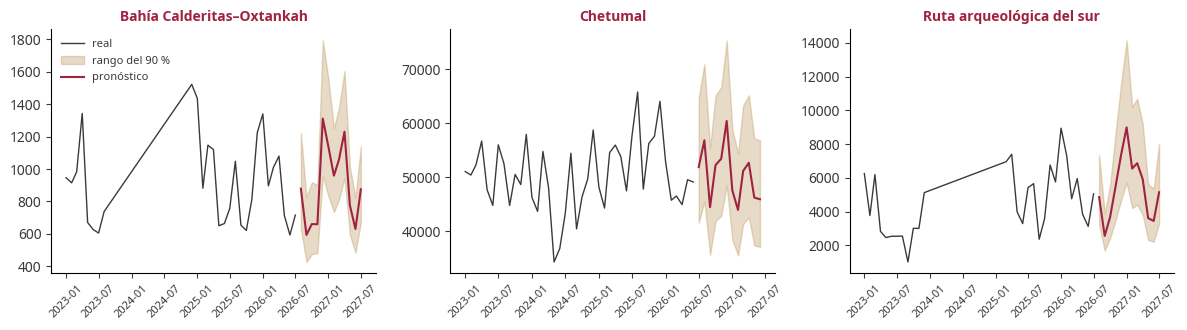

In [19]:
filas = []
for serie, s in series.groupby("serie"):
    s = s.sort_values("periodo").reset_index(drop=True)
    nombre = elegidos.set_index("serie").modelo[serie]
    origen = s.periodo.max()                                           # el último mes publicado
    destinos = pd.date_range(origen + pd.offsets.MonthBegin(1), periods=HORIZONTE, freq="MS")
    pron = MODELOS[nombre](s, origen, destinos)
    err = b[(b.serie == serie) & (b.modelo == nombre)]
    for k, (dd, p_) in enumerate(zip(destinos, pron), start=1):
        tramo = "1–3" if k <= 3 else "4–6" if k <= 6 else "7–12"
        qq = cuantil_conformal(err[err.tramo_h == tramo].error_log.to_numpy())
        filas.append({"serie": serie, "modelo": nombre, "periodo": dd, "esperado_est": p_,
                      "minimo_90_est": p_ * np.exp(-qq), "maximo_90_est": p_ * np.exp(qq)})
f = pd.DataFrame(filas)
coincide("pronóstico de los próximos 12 meses", f[["esperado_est", "minimo_90_est", "maximo_90_est"]],
         pd.read_parquet(GOLD / "pronostico_mes.parquet")[["esperado_est", "minimo_90_est", "maximo_90_est"]])

fig, ejes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, s in zip(ejes, [x for x in f.serie.unique() if "INAH" in x or "Belice" in x]):
    hist = series[(series.serie == s) & series.entrena_flag & (series.periodo >= "2023-01-01")]
    x = f[f.serie == s]
    ax.plot(hist.periodo, hist.valor, color=GRIS, lw=1, label="real")
    ax.fill_between(x.periodo, x.minimo_90_est, x.maximo_90_est, color=DORADO, alpha=0.35, label="rango del 90 %")
    ax.plot(x.periodo, x.esperado_est, color=GUINDA, label="pronóstico")
    ax.set_title(s.split(" · ")[0], fontsize=10); ax.tick_params(axis="x", rotation=45, labelsize=8)
ejes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
guardar(fig, "4_pronostico_12_meses")

## 6. Resumen: todos los hiperparámetros de este notebook

| Modelo | Hiperparámetro | Valor | Por qué | Qué descartamos |
|---|---|---|---|---|
| Clasificador | Rasgos | Índice de hoy, de hace 1 y 2 meses, cambio, mes en círculo, si es del sur | Solo lo que se conoce al predecir | Clima o tipo de cambio del mes siguiente (no se conocen) |
| Clasificador | Clases desbalanceadas | `class_weight="balanced"` y F1-macro | *Saturado* es 10 % de los casos | Exactitud sola |
| Clasificador | Partición | Entrenamiento · validación ago-24 a jul-25 · prueba ago-25 a jul-26 | Elegir y medir con meses distintos | Partición al azar (ve el futuro); elegir con la prueba |
| Clasificador | Criterio | Más aciertos en la validación; a igualdad, más cambios anticipados | La regla anti-colapso necesita anticipar | Solo F1-macro |
| Random Forest | Árboles | 400 | Con 100 da lo mismo; más ya no cambia el voto | Búsqueda en rejilla (con 136 casos, elegir por suerte) |
| Random Forest | Hoja mínima | 3 casos | Hoja ≥ 10 pierde aciertos; hoja 1 queda igual | Árboles sin límite |
| Logística | Regularización | C = 1, rasgos estandarizados | Valor estándar; C = 0.1 y 10 no mejoran | — |
| Pronóstico | Horizonte | 12 meses | El calendario de la campaña es anual | — |
| Pronóstico | Tramo mínimo | 3 meses útiles; < 6 meses sin tendencia | Un nivel con menos de 3 meses no es confiable | Pronosticar justo después de reabrir |
| Holt-Winters | Temporada | Forma del año fija, de años completos previos | No hay 24 meses seguidos tras reabrir | Holt-Winters clásico; STL |
| Holt-Winters | Tendencia | Amortiguada y, aparte, sin tendencia | La tendencia de tramos cortos se dispara | Tendencia lineal sin amortiguar |
| Gradient Boosting | Árboles, tasa, hoja | 150, 0.05, ≥ 20 casos | Pocos datos: aprender despacio | Valores por defecto (sobreajustan) |
| Regresión | Variables | Tramo, mes, lluvia sobre lo normal, tormenta | Lo que explica la temporada y el clima | Tipo de cambio (no se conoce a futuro) |
| Conformal | Nivel | 90 % | El rango "mínimo–máximo esperado" de la página | Intervalos de cada modelo (suponen errores normales) |
| Conformal | Calibración mínima | 20 errores | Con menos, el cuantil 90 es inestable | — |
| Conformal | Por tramo de horizonte | 1–3, 4–6 y 7–12 meses | A 10 meses hay más incertidumbre que a 1 | Un solo tamaño de rango |
| Elección | Regla | Menor MAE con cobertura real ≥ 80 % | Error bajo y rango que cumple | Solo el menor error; un solo modelo para todo |

**Qué decisión alimenta.** El clasificador dice qué lugar pausar antes de que se llene (regla anti-colapso, notebook 6);
el pronóstico, en qué meses hay espacio y cuántos visitantes esperar, con su rango (calendario de la página, Monte Carlo
del notebook 5 y presupuesto del notebook 6).